In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")


### Load the dataset

In [2]:
# The file has no header and is whitespace-separated, so I supplied column names manually
path = "4) house Prediction Data Set.csv"
cols = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE',
        'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'MEDV']

df = pd.read_csv(path, sep=r'\s+', header=None, names=cols)

### Data Quality Check and summary statistics

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    float64
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 55.5 KB


In [4]:
df.describe()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


In [5]:
df.shape

(506, 14)

In [6]:
df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


In [7]:
df.isnull().sum().sum()

np.int64(0)

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
CRIM,506.0,3.613524,8.601545,0.00632,0.082045,0.25651,3.677083,88.9762
ZN,506.0,11.363636,23.322453,0.00000,0.000000,0.00000,12.500000,100.0000
INDUS,506.0,11.136779,6.860353,0.46000,5.190000,9.69000,18.100000,27.7400
CHAS,506.0,0.069170,0.253994,0.00000,0.000000,0.00000,0.000000,1.0000
NOX,506.0,0.554695,0.115878,0.38500,0.449000,0.53800,0.624000,0.8710
RM,506.0,6.284634,0.702617,3.56100,5.885500,6.20850,6.623500,8.7800
AGE,506.0,68.574901,28.148861,2.90000,45.025000,77.50000,94.075000,100.0000
DIS,506.0,3.795043,2.105710,1.12960,2.100175,3.20745,5.188425,12.1265
RAD,506.0,9.549407,8.707259,1.00000,4.000000,5.00000,24.000000,24.0000
TAX,506.0,408.237154,168.537116,187.00000,279.000000,330.00000,666.000000,711.0000


### Target and correlations

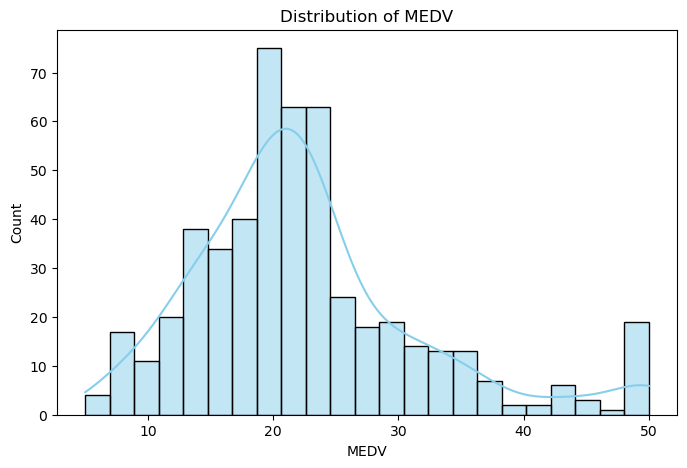

In [10]:
# Distribution of the target (MEDV) before Modelling
plt.figure(figsize=(8, 5))
sns.histplot(df['MEDV'], kde=True, color='skyblue')
plt.title('Distribution of MEDV')
plt.show()

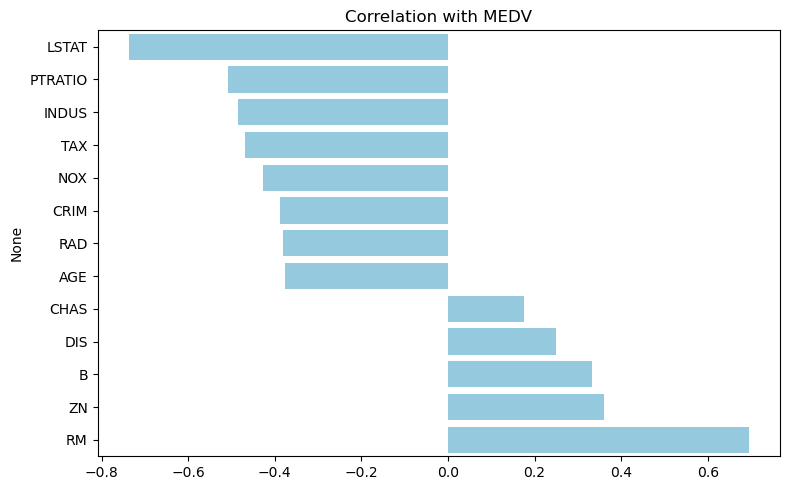

In [11]:
# Which features move with price?
# Sorted correlation of each feature with MEDV
corr_target = df.corr()['MEDV'].drop('MEDV').sort_values()

plt.figure(figsize=(8, 5))
sns.barplot(x=corr_target.values, y=corr_target.index, color='skyblue')
plt.title('Correlation with MEDV')
plt.tight_layout()
plt.show()

### Features Selection and split

In [12]:
# Dropping B (a derived feature with ethuical concerns) and separate it from the target
X = df.drop(columns=['MEDV', 'B'])
y = df['MEDV']


In [13]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(X_train.shape, X_test.shape)

(404, 12) (102, 12)


#### Scaling and fitting the train data

In [14]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [15]:
# Baseline models (Linear Regression and Random Forest)
# Linear Regression gets the scaled data, while Random Forest doesn't need scaling
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

lr = LinearRegression()
lr.fit(X_train_scaled, y_train)     # linear model uses scaled data

rf = RandomForestRegressor(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)            # trees don't need scaling

pred_lr = lr.predict(X_test_scaled)
pred_rf = rf.predict(X_test)

In [16]:
# Evaluate the two baselines on the test set
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

# R2 = variance explained, MAE = average error, RMSE = error that penalizes large misses
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'R2': [r2_score(y_test, pred_lr), r2_score(y_test, pred_rf)],
    'MAE': [mean_absolute_error(y_test, pred_lr), mean_absolute_error(y_test, pred_rf)],
    'RMSE': [np.sqrt(mean_squared_error(y_test, pred_lr)), np.sqrt(mean_squared_error(y_test, pred_rf))]
})
results.round(3)

,Model,R2,MAE,RMSE
0,Linear Regression,0.689,3.111,4.773
1,Random Forest,0.881,2.044,2.959


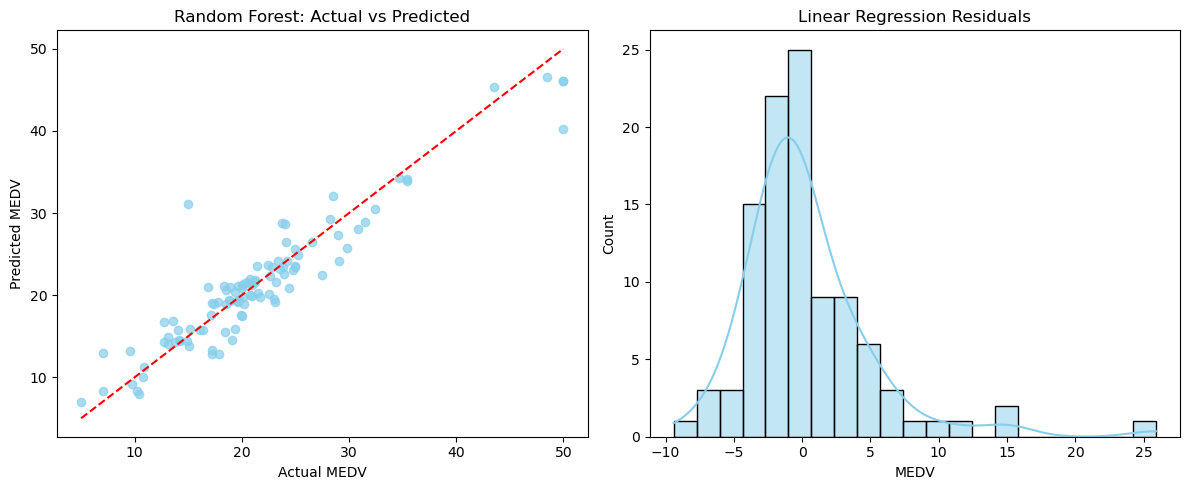

In [17]:
# Baseline diagnostics to see where the baseline went wrong
plt.figure(figsize=(12, 5))

# Left: points close to the red line mean accurate predictions
plt.subplot(1, 2, 1)
plt.scatter(y_test, pred_rf, alpha=0.7, color='skyblue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Actual MEDV'); plt.ylabel('Predicted MEDV')
plt.title('Random Forest: Actual vs Predicted')

# Right: residuals should be centered on zero with no pattern
plt.subplot(1, 2, 2)
sns.histplot(y_test - pred_lr, kde=True, color='skyblue')
plt.title('Linear Regression Residuals')

plt.tight_layout()
plt.show()

In [18]:
# See what drives each baseline: linear coefficients (direction) and forest importances (share of decisions)
coef = pd.Series(lr.coef_, index=X.columns).sort_values()
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
print(coef, '\n\n', imp)

LSTAT     -3.819016
DIS       -3.119459
NOX       -2.137599
PTRATIO   -1.991871
TAX       -1.871317
CRIM      -1.127473
AGE       -0.100500
INDUS      0.173858
ZN         0.712109
CHAS       0.787152
RAD        2.058898
RM         3.004420
dtype: float64 

 CHAS       0.001398
ZN         0.002012
RAD        0.005323
INDUS      0.007029
AGE        0.015959
NOX        0.016713
TAX        0.016913
PTRATIO    0.017396
CRIM       0.041133
DIS        0.056129
LSTAT      0.326968
RM         0.493027
dtype: float64


### Importing more Models

In [19]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.model_selection import cross_val_score

### Defining the models

In [20]:
models = {
    'Linear Regression': (LinearRegression(), True),
    'Ridge': (Ridge(alpha=1.0), True),
    'Lasso': (Lasso(alpha=0.1), True),
    'KNN': (KNeighborsRegressor(n_neighbors=5), True),
    'SVR': (SVR(kernel='rbf', C=10), True),
    'Decision Tree': (DecisionTreeRegressor(max_depth=6, random_state=42), False),
    'Random Forest': (RandomForestRegressor(n_estimators=200, random_state=42), False),
    'Gradient Boosting': (GradientBoostingRegressor(n_estimators=200, random_state=42), False),
}

### Training all Models

In [21]:
predictions = {}

for name, (model, scaled) in models.items():
    Xtr = X_train_scaled if scaled else X_train
    Xte = X_test_scaled if scaled else X_test

    model.fit(Xtr, y_train)
    predictions[name] = model.predict(Xte)
    print(f"{name} trained")

Linear Regression trained
Ridge trained
Lasso trained
KNN trained
SVR trained
Decision Tree trained
Random Forest trained
Gradient Boosting trained


### Cross-Validation

In [22]:
# A single 80/20 split can be lucky, so we also run 5-fold cross-validation for a steadier score
cv_scores = {}

for name, (model, scaled) in models.items():
    Xtr = X_train_scaled if scaled else X_train
    cv_scores[name] = cross_val_score(model, Xtr, y_train, cv=5, scoring='r2').mean()
    print(f"{name}: CV R2 = {cv_scores[name]:.3f}")

Linear Regression: CV R2 = 0.715
Ridge: CV R2 = 0.715
Lasso: CV R2 = 0.708
KNN: CV R2 = 0.728
SVR: CV R2 = 0.834
Decision Tree: CV R2 = 0.655
Random Forest: CV R2 = 0.824
Gradient Boosting: CV R2 = 0.846


### Building a comparison Table

In [23]:
# Putting the CV scores side by side, sorted by R2
rows = []

for name, pred in predictions.items():
    rows.append({
        'Model': name,
        'R2': r2_score(y_test, pred),
        'CV R2': cv_scores[name],
        'MAE': mean_absolute_error(y_test, pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, pred))
    })

results_all = pd.DataFrame(rows).sort_values('R2', ascending=False).reset_index(drop=True)
results_all.round(3)

,Model,R2,CV R2,MAE,RMSE
0,Gradient Boosting,0.917,0.846,1.877,2.468
1,Random Forest,0.881,0.824,2.044,2.959
2,Decision Tree,0.874,0.655,2.419,3.040
3,SVR,0.822,0.834,2.049,3.617
4,KNN,0.719,0.728,2.625,4.540
5,Linear Regression,0.689,0.715,3.111,4.773
6,Ridge,0.689,0.715,3.107,4.776
7,Lasso,0.667,0.708,3.168,4.941


### R2 Plot

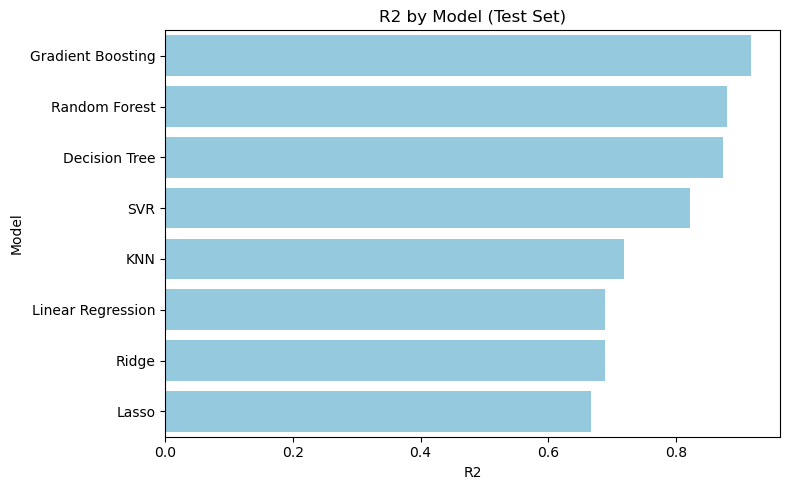

In [24]:
# R2 chart of the table above, to see the gap between model families at a glance
plt.figure(figsize=(8, 5))
sns.barplot(data=results_all, x='R2', y='Model', color='skyblue')
plt.title('R2 by Model (Test Set)')
plt.tight_layout()
plt.show()

### RSME PLOT

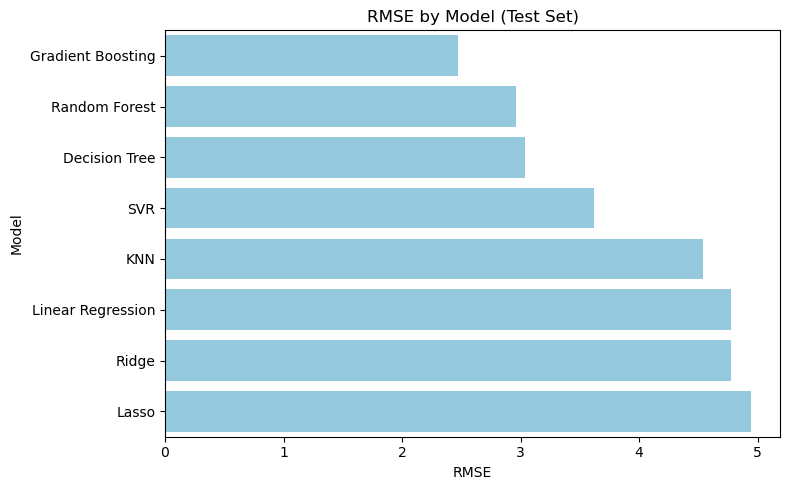

In [25]:
# RMSE chart, the same comparison in error terms (lower is better)
plt.figure(figsize=(8, 5))
sns.barplot(data=results_all, x='RMSE', y='Model', color='skyblue')
plt.title('RMSE by Model (Test Set)')
plt.tight_layout()
plt.show()

### Lasso Coefficients

In [26]:
# Lasso can shrink useless features to exactly zero, so its coefficients show which features it dropped
lasso_coef = pd.Series(models['Lasso'][0].coef_, index=X.columns).sort_values()
lasso_coef

LSTAT     -3.785145
DIS       -2.326771
PTRATIO   -1.852338
NOX       -1.681049
CRIM      -0.830191
TAX       -0.506835
INDUS     -0.000000
AGE       -0.000000
ZN         0.277040
RAD        0.517564
CHAS       0.757061
RM         3.162588
dtype: float64

### Tuning setup

In [27]:
# Gradient Boosting performed better, so I tune it with a small grid over trees, learning rate and depth
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.05, 0.1],
    'max_depth': [2, 3, 4]
}

grid = GridSearchCV(GradientBoostingRegressor(random_state=42),
                    param_grid, cv=5, scoring='r2', n_jobs=-1)

### Running the search

In [28]:
grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print("Best CV R2:", round(grid.best_score_, 3))

Best params: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 300}
Best CV R2: 0.848


### Evaluate the model

In [29]:
# Score the tuned model on the unseen test set
best_pred = grid.best_estimator_.predict(X_test)

print("Test R2:", round(r2_score(y_test, best_pred), 3))
print("Test MAE:", round(mean_absolute_error(y_test, best_pred), 3))
print("Test RMSE:", round(np.sqrt(mean_squared_error(y_test, best_pred)), 3))

Test R2: 0.909
Test MAE: 1.897
Test RMSE: 2.581


In [30]:
# Step 23: Feature importance of the tuned GS model to confirm what drives its predictions 
best_gb = grid.best_estimator_
imp_gb = pd.Series(best_gb.feature_importances_, index=X.columns).sort_values()
imp_gb

ZN         0.000421
CHAS       0.000469
INDUS      0.002019
RAD        0.002508
TAX        0.013076
AGE        0.019203
PTRATIO    0.027817
CRIM       0.029920
NOX        0.035091
DIS        0.075567
LSTAT      0.386317
RM         0.407592
dtype: float64

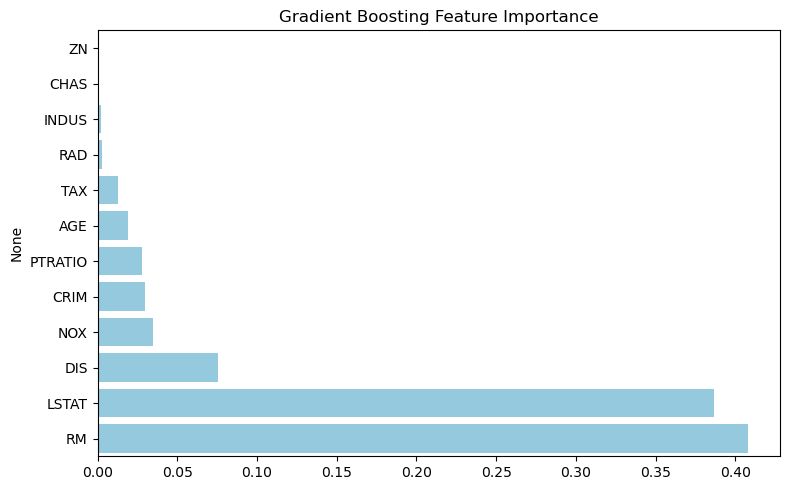

In [31]:
# Plot feature importance
plt.figure(figsize=(8, 5))
sns.barplot(x=imp_gb.values, y=imp_gb.index, color='skyblue')
plt.title('Gradient Boosting Feature Importance')
plt.tight_layout()
plt.show()

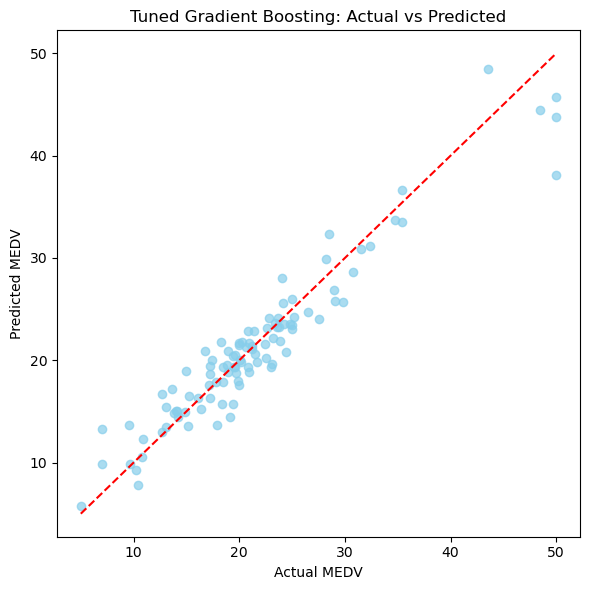

In [32]:
# Final model - actual vs predicted 
# Points hugging the red line mean accurate predictions
plt.figure(figsize=(6, 6))
plt.scatter(y_test, best_pred, alpha=0.7, color='skyblue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Actual MEDV')
plt.ylabel('Predicted MEDV')
plt.title('Tuned Gradient Boosting: Actual vs Predicted')
plt.tight_layout()
plt.show()

In [33]:
# RAD and TAX look related, so we check their correlation to justify the limitation in the conclusion
df[['RAD', 'TAX']].corr()

,RAD,TAX
RAD,1.000000,0.910228
TAX,0.910228,1.000000


## Findings and Conclusion

**Objective:** Predict median house value (MEDV) and compare multiple regression models.

**Setup:** 506 records, 12 predictors (the `B` column was dropped because it is a derived feature with ethical concerns). 80/20 train-test split, features scaled for the scale-sensitive models (fit on training data only), and 5-fold cross-validation used alongside test scores.

**Results**

| Model | Test R² | CV R² | RMSE |
|---|---|---|---|
| Gradient Boosting (tuned) | 0.909 | 0.848 | 2.581 |
| Gradient Boosting | 0.917 | 0.846 | 2.468 |
| Random Forest | 0.881 | 0.824 | 2.959 |
| Decision Tree | 0.874 | 0.655 | 3.040 |
| SVR | 0.822 | 0.834 | 3.617 |
| KNN | 0.719 | 0.728 | 4.540 |
| Linear Regression | 0.689 | 0.715 | 4.773 |
| Ridge | 0.689 | 0.715 | 4.776 |
| Lasso | 0.667 | 0.708 | 4.941 |

**Key findings**
1. **Gradient Boosting performed best** (CV R² 0.85, RMSE about 2.5 untuned and 2.6 tuned, a typical error of roughly $2,500 to $2,600), followed by Random Forest. Tree ensembles outperformed linear and distance-based models, which points to nonlinear relationships in the data.
2. **The single Decision Tree overfit.** Its test R² (0.874) is far above its CV R² (0.655), so its test score was partly luck. The ensembles stayed stable.
3. **Regularization added nothing.** Ridge matched plain Linear Regression and Lasso was slightly lower, as there is little overfitting to correct with 12 features. Lasso did shrink `INDUS` and `AGE` to zero.
4. **Main drivers:** room count (`RM`) raises prices, while neighborhood status (`LSTAT`), distance to employment centres (`DIS`), pupil-teacher ratio and pollution (`NOX`) lower them. The tree models (RM importance about 0.41 to 0.49, LSTAT about 0.33 to 0.39) and Lasso rank `RM` and `LSTAT` first and second. In plain Linear Regression `DIS` (-3.12) edges out `RM` (+3.00), likely because correlated features share credit.
5. **Hyperparameter tuning gave a negligible gain** in CV R² (0.846 to 0.848) and slightly lowered the test R² (0.917 to 0.909), so the default configuration was already near-optimal. The test dip is within normal variation for a 102-row test set.

**Limitations**
- Prices are capped at 50 in this dataset, which limits accuracy for expensive homes.
- `RAD` and `TAX` are highly correlated (r = 0.910228), so their individual linear coefficients are unreliable.
- The dataset is small (about 500 rows), and test scores come from a single split, so CV scores are the more trustworthy estimate.

**Conclusion:** Gradient Boosting (tuned, test R² 0.909, RMSE 2.58) is the recommended model for this dataset, with room count and neighborhood status as the dominant predictors.